# Benchmarking Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 26.01.2025
- Date of Last Modification: 16.12.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nichejepa conda environment, installable from ```../../envs/nichejepa.yaml```.

## 1. Setup

### 1.1 Load Libraries 

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys
sys.path.append("../../utils")

In [ ]:
import os
import re
import warnings
from collections import OrderedDict

import anndata as ad
import pandas as pd
import scanpy as sc
from matplotlib.lines import Line2D

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

### 1.2 Configure Paths

In [ ]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

### 1.4 Run Notebook Setup

In [ ]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [ ]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [ ]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [ ]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [ ]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)

## 2. Data Visualization

### 2.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

In [ ]:
# Define dataset params
dataset_name = 'chl59-8b_1p'
batches = ['Lung9_Rep1',
           'Lung9_Rep2',
           'Lung5_Rep1',
           'Lung5_Rep2',
           'Lung6',
           'Lung12']
niche_key = 'niche'
batch_key = 'batch'
spot_sizes = [80 * 0.18] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]

            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.18 # conversion rate from https://nanostring-public-share.s3.us-west-2.amazonaws.com/SMI-Compressed/SMI-ReadMe.html

In [ ]:
adata.obs[niche_key].unique()

In [ ]:
# Plot ground truth niches

# Label niches (based on NicheCompass reproducibility repo)
label2niche = {
    '0': '1- Tumor (stroma border)',
    '2': '2- Tumor interior',
    '5': '3- Tumor (neutrophil border)',
    '7': '4- Tumor interior',
    '11': '5- Infiltrated tumor',
    '3': '6- Tumor-infiltrating neutrophils',
    '4': '7- Neutrophil expansion',
    '1': '8- Stroma',
    '6': '9- Plasmablast rich stroma',
    '9': '10- Lymphoid rich stroma',
    '8': '11- Lymphoid aggregates',
    '10': '12- Macrophage rich stroma'
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

### 2.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Define dataset params
dataset_name = 'chr78-11b_1p'
batches = ['CM007',
           'CM008',
           'CM009',
           'CM011',
           'CM013',
           'CM015',
           'CM016',
           'CM017',
           'CM018',
           'CM019',
           'CM020']
niche_key = 'broad_anatomy'
batch_key = 'batch'
spot_sizes = [240 * 0.093] * len(batches)

In [ ]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial'] * 0.093 # conversion rate from Valentina

In [ ]:
# Combine regions
adata.obs[niche_key] = adata.obs[niche_key].apply(lambda x: x.replace('Urogenital Sinus', 'UrogenitalSinus'))

In [ ]:
# Plot ground truth niches

# Label niches
label2niche = {
    '0': 'Adrenal',
    '1': 'Cervix',
    '2': 'Ducts',
    '3': 'Epididymis',
    '4': 'Epoophron',
    '5': 'External Genitalia',
    '6': 'FallopianTube',
    '7': 'Genital Tubercle',
    '8': 'Gonad',
    '9': 'LabioScrotal Swelling',
    '10': 'LowerTract',
    '11': 'Nephros',
    '12': 'Testis',
    '13': 'Unassigned',
    '14': 'UpperVagina',
    '15': 'Urogenital Sinus',
    '16': 'UrogenitalSinus',
    '17': 'Uterus',
    '18': 'VaginalPlate',
    '19': 'Vas Deferens',
    '20': 'Background', # < 100 cells
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

### 2.3 xhs49-1b_1p (Xenium Human Melanoma)

In [ ]:
dataset_name = 'xhs49-1b_1p'
niche_key = 'niche_name'
spot_size = 20

In [ ]:
adata = sc.read_h5ad(f'{st_data_silver_folder_path}/{dataset_name}/Xenium_Prime_Human_Skin_FFPE_outs.h5ad')

# Filter cells without niche labels
adata = adata[~adata.obs['niche_name'].isna()]

In [ ]:
adata.obs['niche_name'].value_counts()

In [ ]:
# Plot ground truth niches

# Label niches
label2niche = {
    '0': 'Epidemis',
    '1': 'Superficial dermis',
    '2': 'Melanoma+infiltrate',
    '3': 'Melanoma',
    '4': 'Immune infiltrate Thi',
    '5': 'Immune infiltrate Mac hi',
    '6': 'Macrophage_fat_region',
    '7': 'Melanoma+blood vessels'
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

file_name = f'{dataset_name}_groundtruth_niches.svg'
sc.pl.spatial(adata,
              color=niche_key,
              palette=pred_palette,
              spot_size=spot_size,
              save=file_name)

### 2.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

In [92]:
# Define dataset params
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11',
           'batch19',
           'batch32']
niche_key = 'niche_type'
batch_key = 'sample'
spot_sizes = [20] * len(batches)

In [93]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata.obs['batch'] = adata.obs['cell_id'].apply(lambda x: x.split('_')[0] + x.split('_')[1])
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)
adata.obsm['spatial'] = adata.obsm['spatial']

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/tmp/ipykernel_122022/1205407707.py:28: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


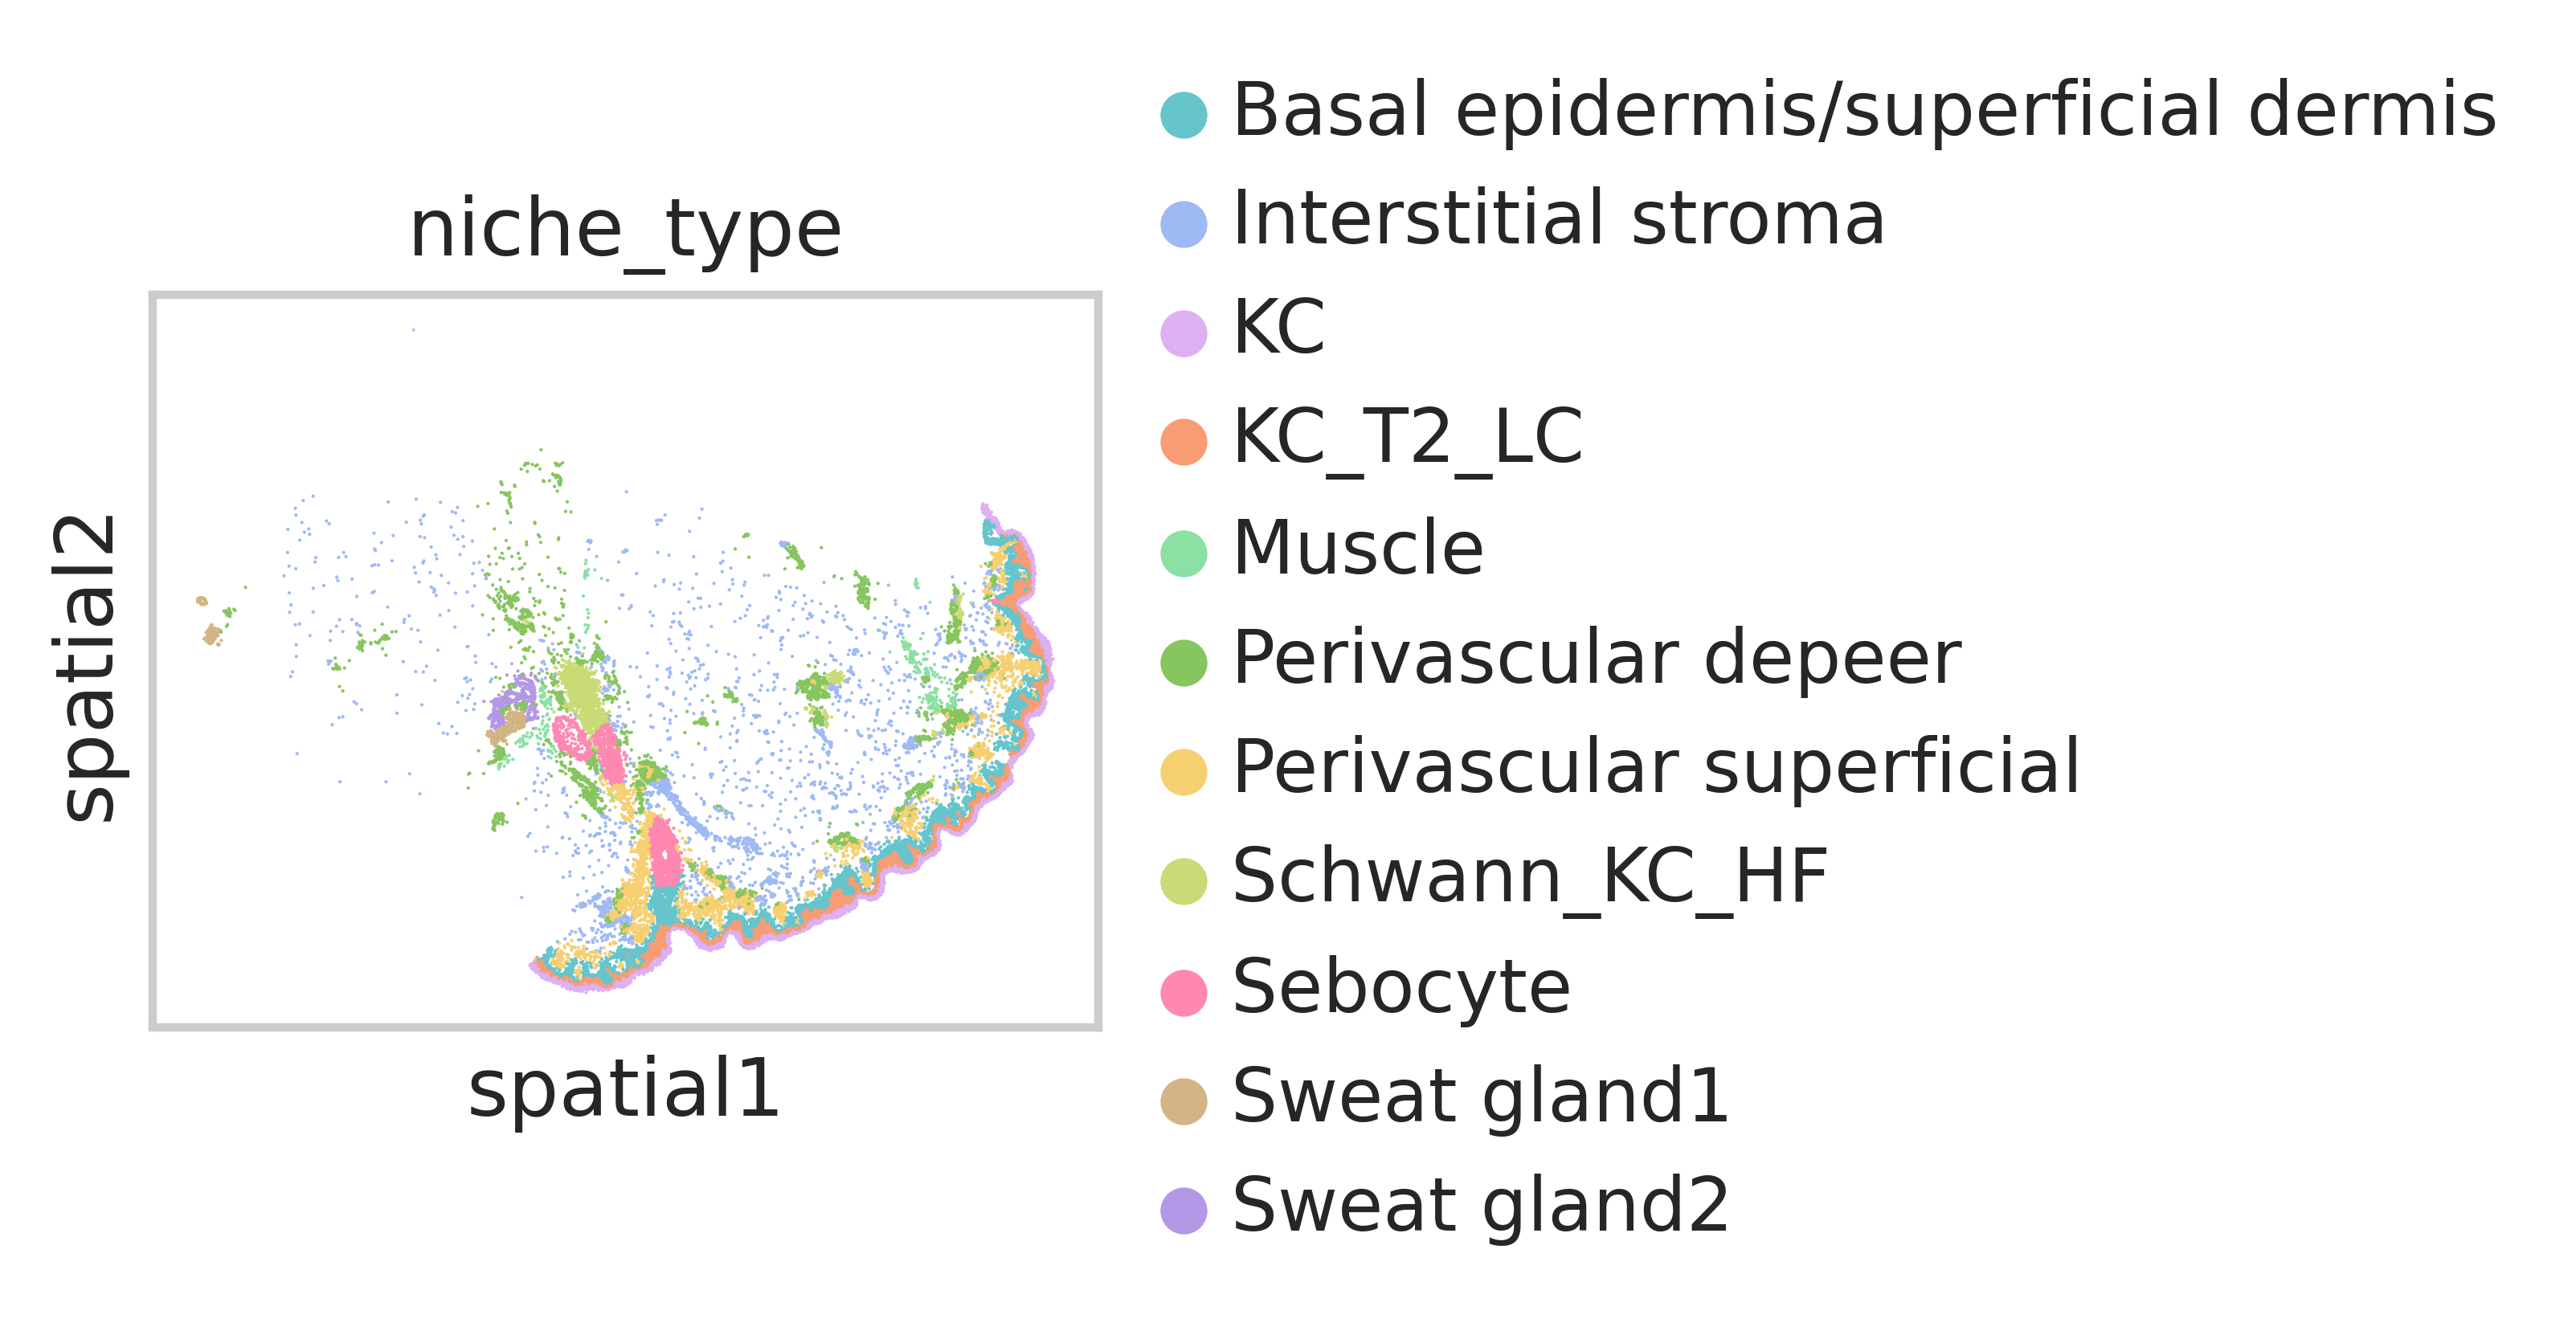

/tmp/ipykernel_122022/1205407707.py:28: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


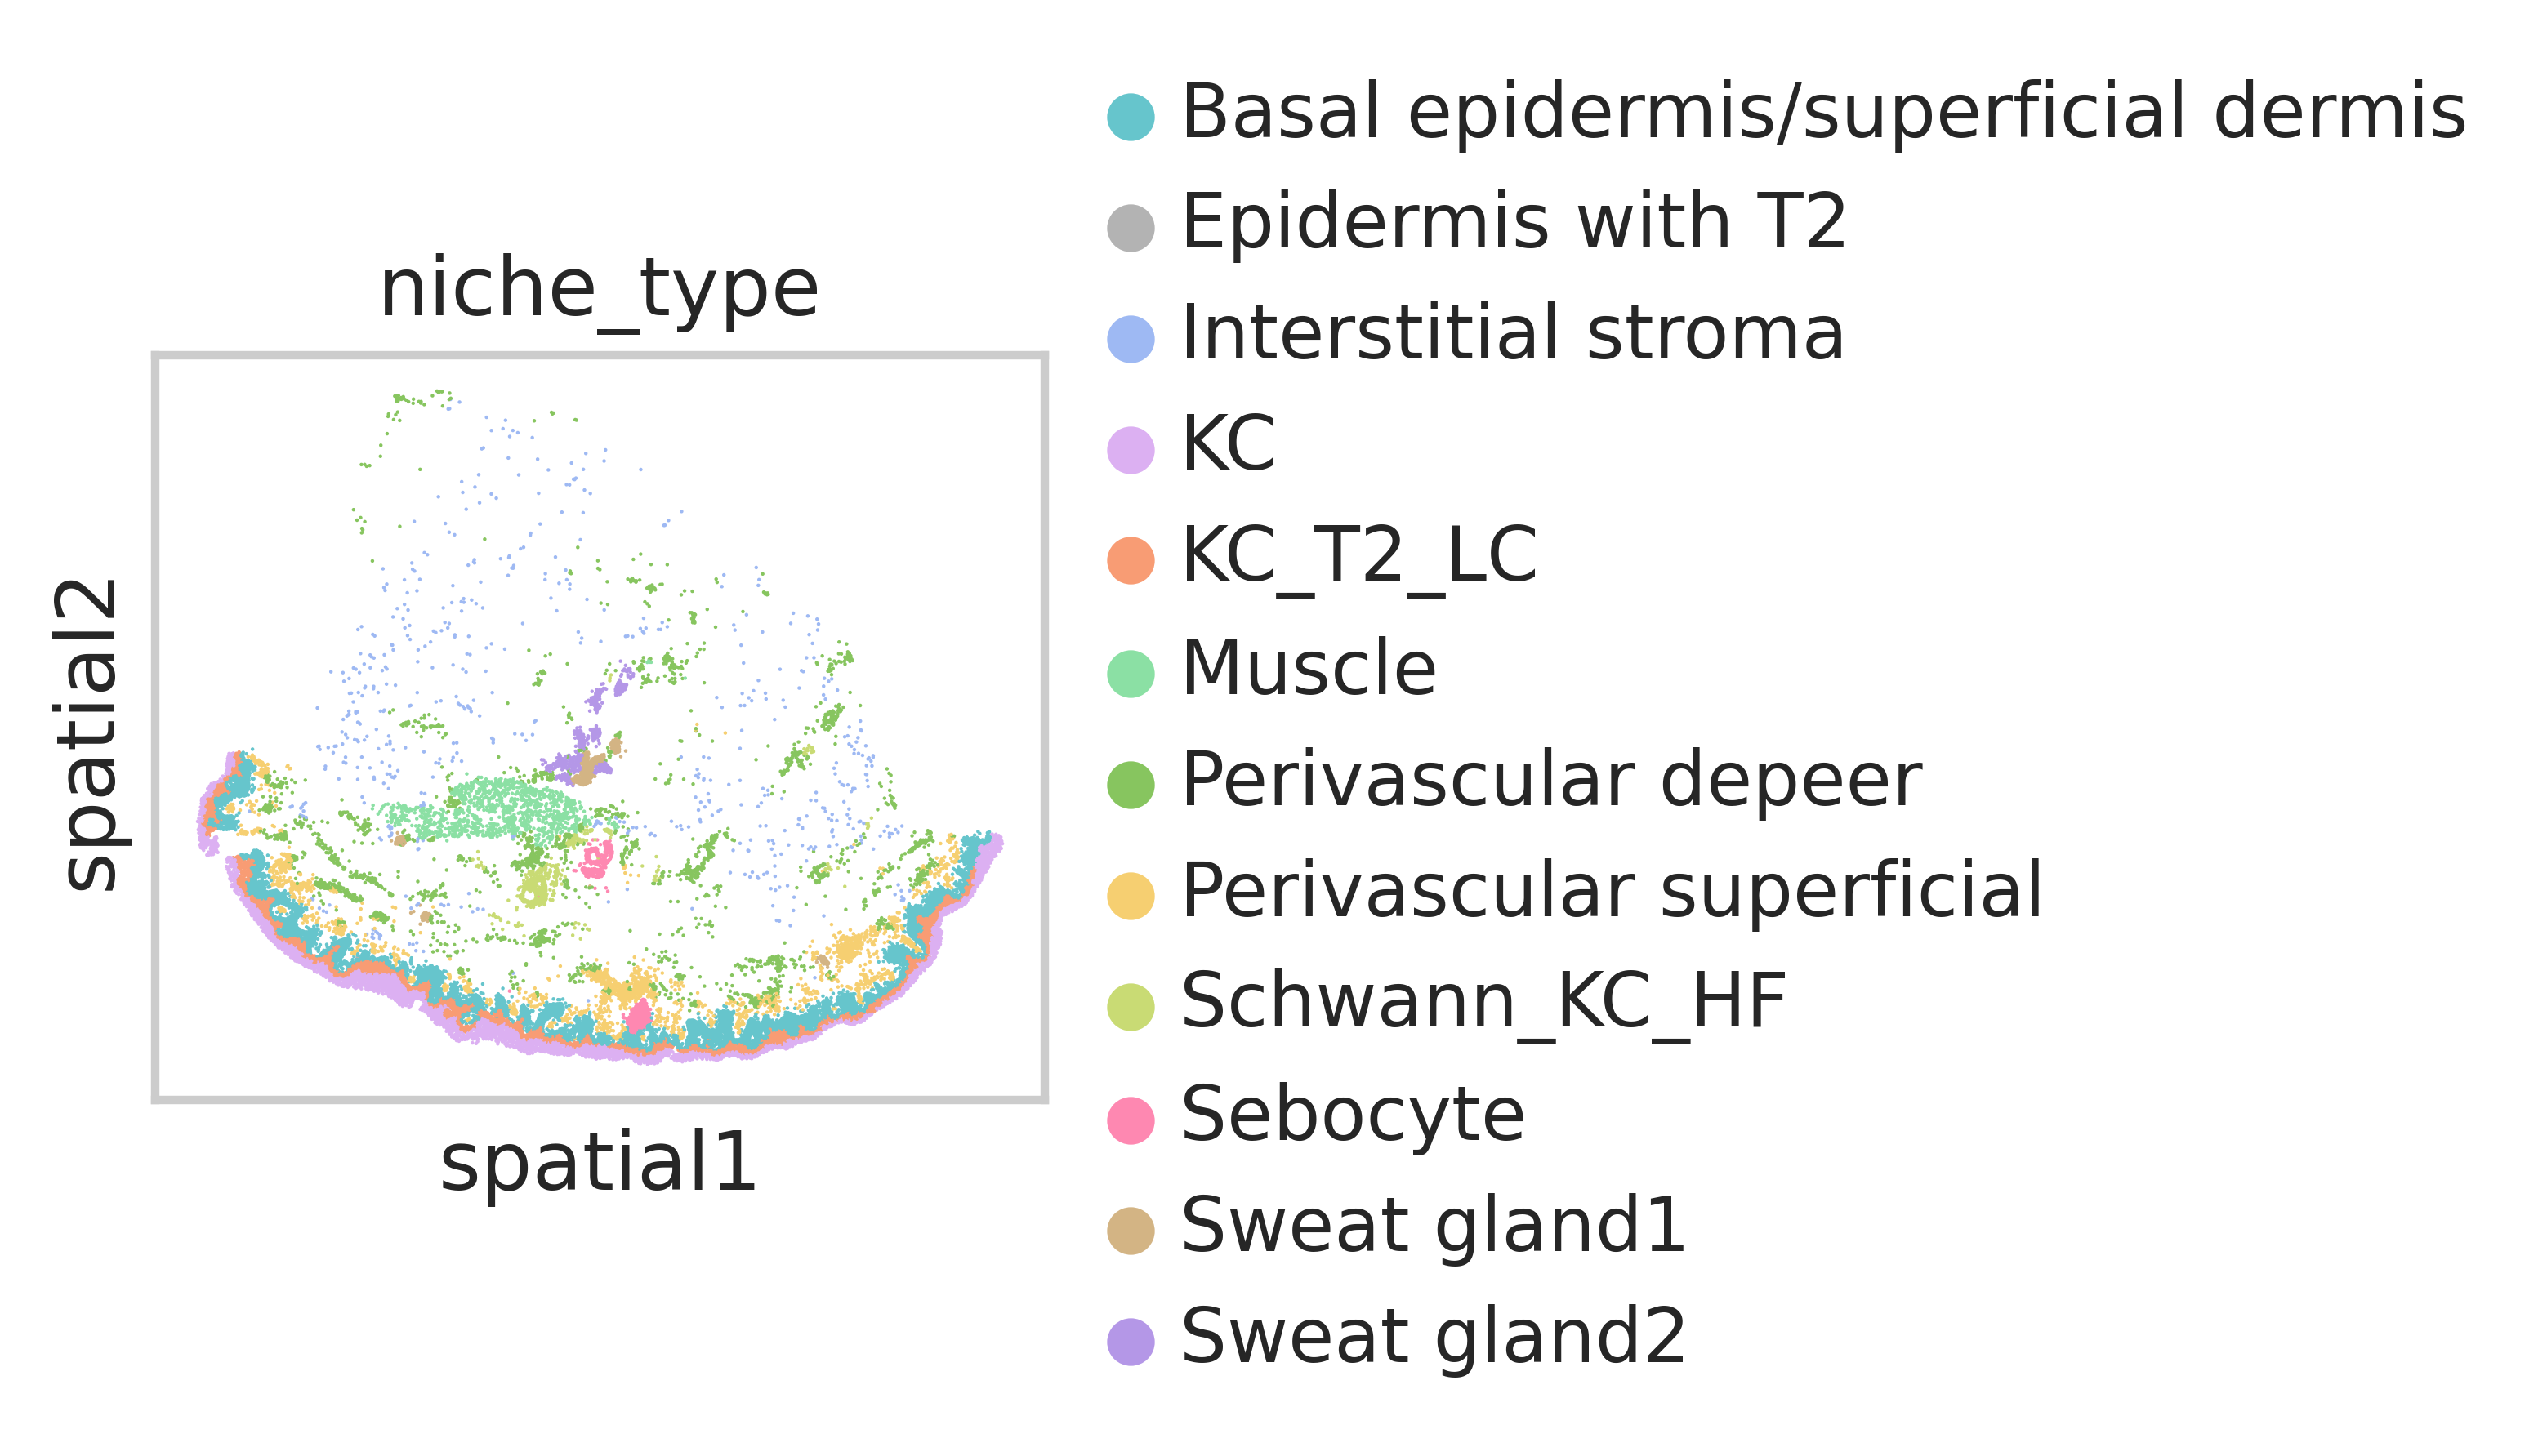

/tmp/ipykernel_122022/1205407707.py:28: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_batch,
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


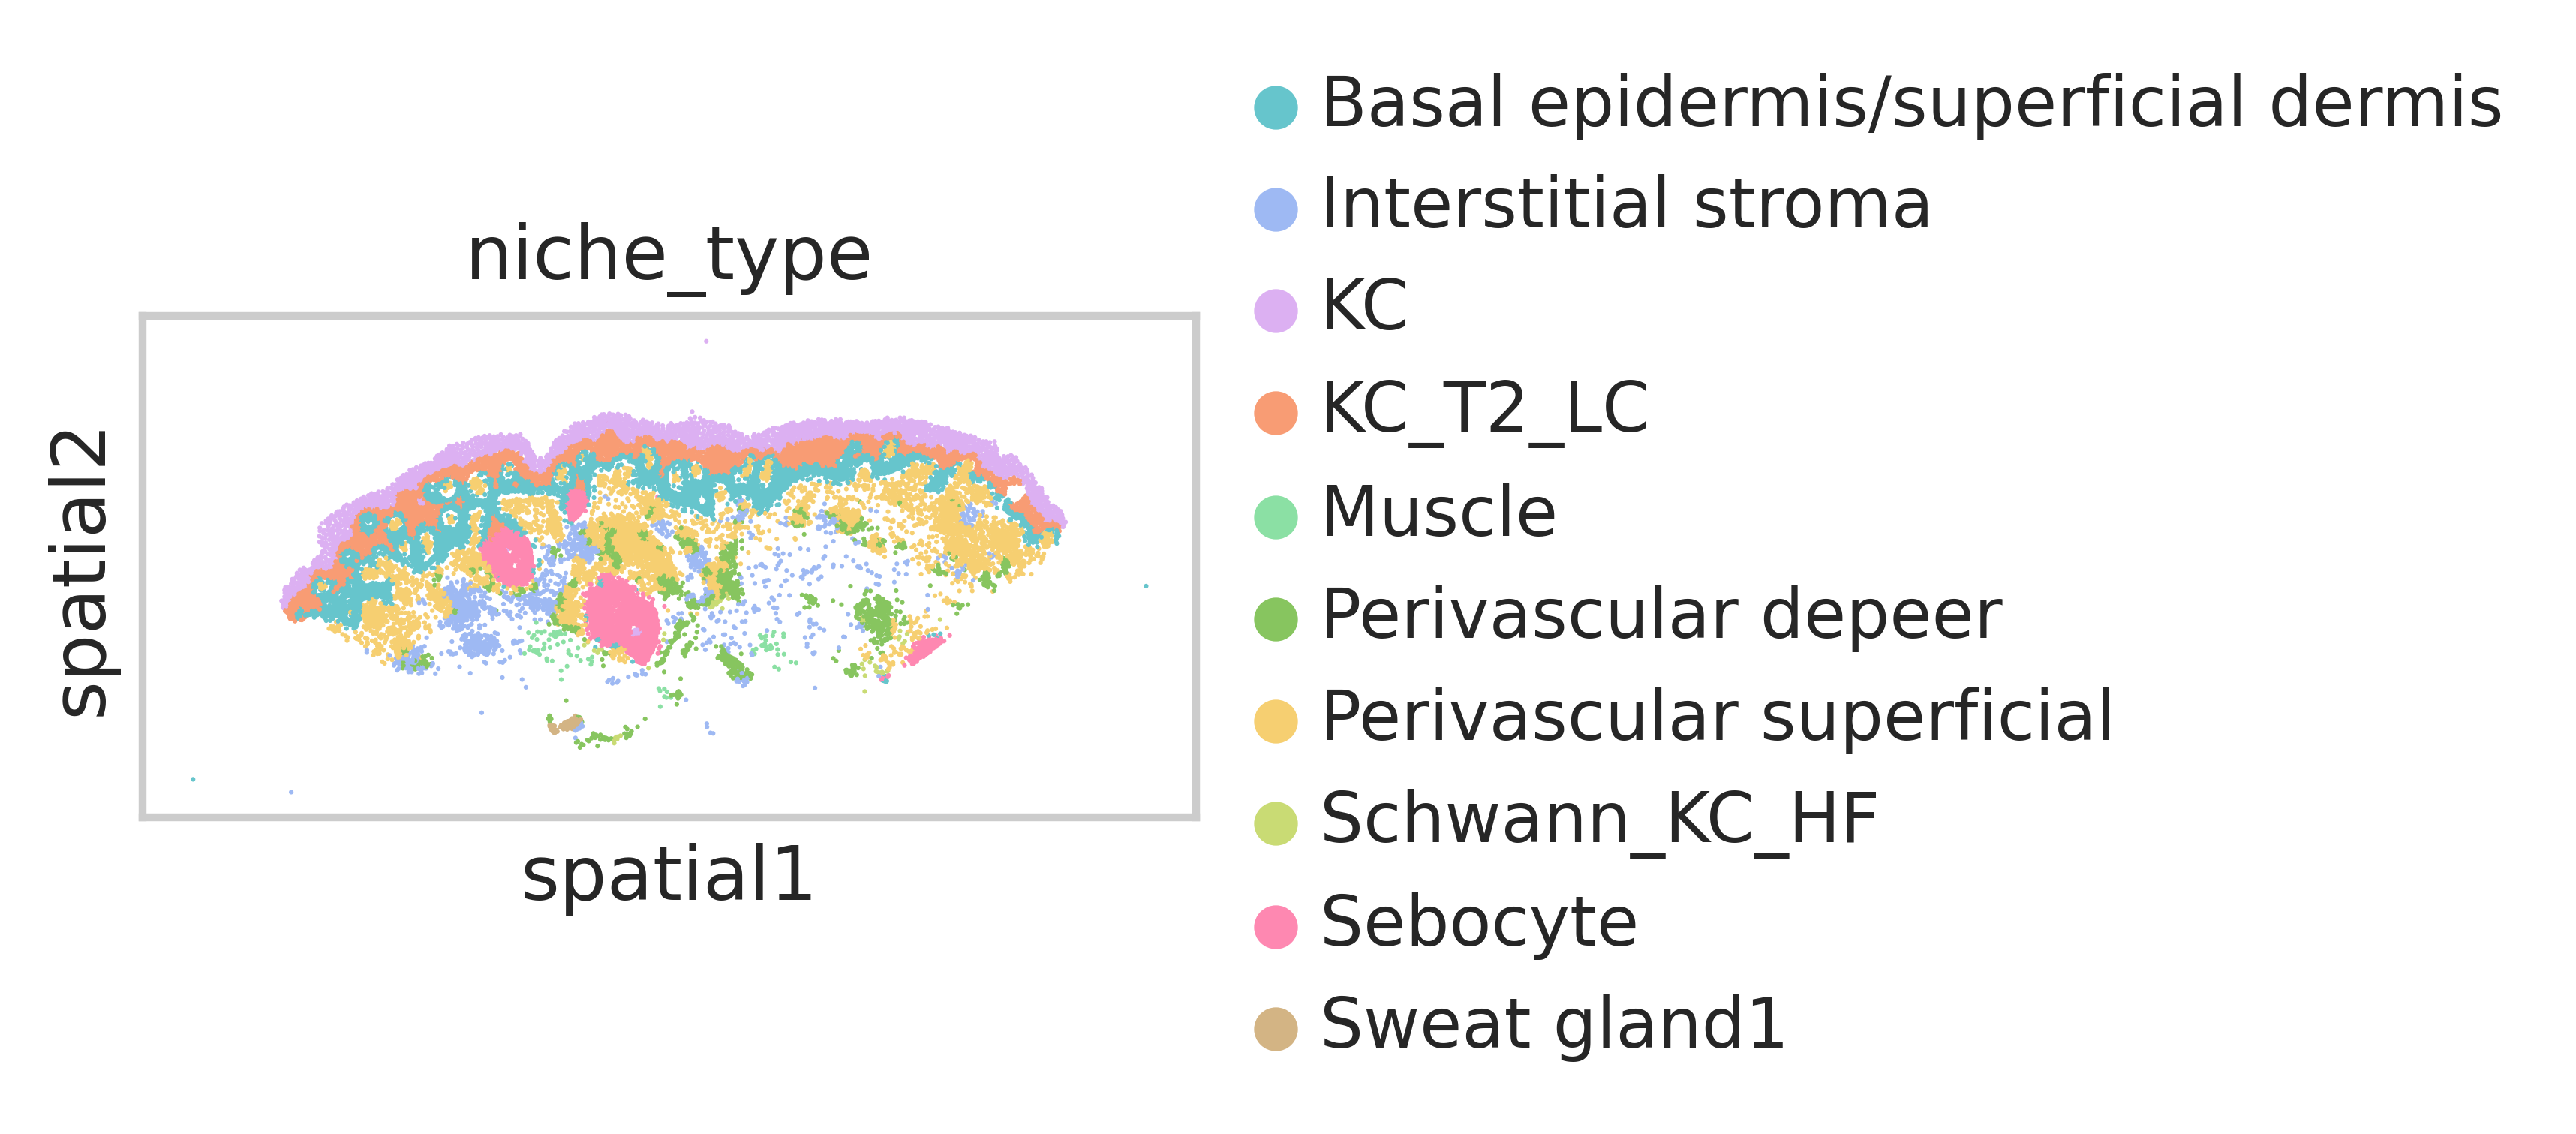

In [94]:
# Plot ground truth niches

# Label niches
label2niche = {
    '0': 'Basal epidermis/superficial dermis',
    '1': 'Perivascular superficial',
    '2': 'KC_T2_LC',
    '3': 'KC',
    '4': 'Perivascular depeer',
    '5': 'Interstitial stroma',
    '6': 'Sebocyte',
    '7': 'Schwann_KC_HF',
    '8': 'Muscle',
    '9': 'Sweat gland2',
    '10': 'Sweat gland1',
    '11': 'Epidermis with T2'
}

pred_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'{dataset_name}_{batch_id}_groundtruth_niches.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=pred_palette,
                  spot_size=spot_sizes[i],
                  save=file_name)

## 3. Niche Identification Metric Comparisons

In [75]:
nichejepa_model_timestamp = '01112025_081731_614'

nichejepa_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
cellplm_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_cellplm_metric_scores.csv')
cellplm_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_cellplm_metric_scores.csv')
cellplm_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_cellplm_metric_scores.csv')
cellplm_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_cellplm_metric_scores.csv')
nicheformer_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nicheformer_metric_scores.csv')
nicheformer_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_nicheformer_metric_scores.csv')
nicheformer_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nicheformer_metric_scores.csv')
novae_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_novae_metric_scores.csv')
novae_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_novae_metric_scores.csv')
novae_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_novae_metric_scores.csv')
novae_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_novae_metric_scores.csv')
scgptspatial_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_scgpt-spatial_metric_scores.csv')

nichejepa_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
nichejepa_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
nichejepa_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
nichejepa_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'
cellplm_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
cellplm_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
cellplm_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
cellplm_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'
nicheformer_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
nicheformer_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
nicheformer_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
novae_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
novae_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
novae_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
novae_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'
scgptspatial_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
scgptspatial_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
scgptspatial_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
scgptspatial_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'

nichejepa_1000_df['method'] = 'NEMO'
nichejepa_49_df['method'] = 'NEMO'
nichejepa_59_df['method'] = 'NEMO'
nichejepa_78_df['method'] = 'NEMO'
cellplm_1000_df['method'] = 'CellPLM'
cellplm_49_df['method'] = 'CellPLM'
cellplm_59_df['method'] = 'CellPLM'
cellplm_78_df['method'] = 'CellPLM'
nicheformer_1000_df['method'] = 'Nicheformer'
nicheformer_49_df['method'] = 'Nicheformer'
nicheformer_59_df['method'] = 'Nicheformer'
novae_1000_df['method'] = 'Novae'
novae_49_df['method'] = 'Novae'
novae_59_df['method'] = 'Novae'
novae_78_df['method'] = 'Novae'
scgptspatial_1000_df['method'] = 'scGPT-spatial'
scgptspatial_49_df['method'] = 'scGPT-spatial'
scgptspatial_59_df['method'] = 'scGPT-spatial'
scgptspatial_78_df['method'] = 'scGPT-spatial'

df = pd.concat([nichejepa_1000_df,
                nichejepa_59_df,
                nichejepa_49_df,
                nichejepa_78_df,
                cellplm_1000_df,
                cellplm_59_df,
                cellplm_49_df,
                cellplm_78_df,
                nicheformer_1000_df,
                nicheformer_59_df,
                nicheformer_49_df,
                novae_1000_df,
                novae_59_df,
                novae_49_df,
                novae_78_df,
                scgptspatial_1000_df,
                scgptspatial_59_df,
                scgptspatial_49_df,
                scgptspatial_78_df],
               ignore_index=True)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# Update plot settings
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

for metric in ["NMI", "ARI"]:
    # Initialize the matplotlib figure with a specific size (wider plot)
    plt.figure(figsize=(10, 4))  # Increased width for a wider plot
    
    # Define a color palette (optional: customize as needed)
    palette = "Set2"
    
    # Create the boxplot
    ax = sns.boxplot(
        x='dataset',
        y=metric,
        hue='method',
        data=df,
        palette=palette,
        dodge=True,
        showfliers=False  # Hide outliers for a cleaner look
    )
    
    # Overlay the scatter points with the same hue and palette
    sns.stripplot(
        x='dataset',
        y=metric,
        hue='method',
        data=df,
        dodge=True,
        jitter=True,
        alpha=0.7,
        size=8,  # Increased dot size
        marker='o',
        edgecolor='black',  # Changed to black edges
        linewidth=1,        # Add linewidth for better edge visibility
        palette=palette,    # Ensure the palette matches the boxplot
        ax=ax
    )
    
    # Handle the legend to avoid duplicates
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))  # Remove duplicate labels
    
    # Remove the existing legend
    ax.legend_.remove()
    
    # Create custom legend handles with desired properties
    unique_methods = list(by_label.keys())
    palette_colors = sns.color_palette(palette, n_colors=len(unique_methods))
    
    custom_handles = [
        Line2D([0], [0], marker='o', color='w', label=method,
               markerfacecolor=palette_colors[i],
               markeredgecolor='black', markersize=10)
        for i, method in enumerate(unique_methods)
    ]
    
    # Add the custom legend
    ax.legend(handles=custom_handles, title='Method')
    
    # Add titles and labels with appropriate font sizes
    plt.title(f'{metric} Distribution per Dataset and Method')
    plt.xlabel('Dataset')
    plt.ylabel(metric)
    
    # Add black striped lines between x-axis values (datasets)
    num_datasets = len(df['dataset'].unique())
    for i in range(num_datasets - 1):
        ax.axvline(x=i + 0.5, color='black', linestyle='--', linewidth=2)  # Dashed black lines
    
    # Adjust layout for better fit and prevent clipping of labels
    plt.tight_layout()
    
    # Display the plot
    plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison_{metric.lower()}_{nichejepa_model_timestamp}.svg', dpi=300)
    plt.show()

In [ ]:
nichejepa_model_timestamp = '01112025_081731_614'

nichejepa_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
nichejepa_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_nichejepa_metric_scores_{nichejepa_model_timestamp}.csv')
cellplm_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_cellplm_metric_scores.csv')
cellplm_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_cellplm_metric_scores.csv')
cellplm_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_cellplm_metric_scores.csv')
cellplm_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_cellplm_metric_scores.csv')
nicheformer_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_nicheformer_metric_scores.csv')
nicheformer_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_nicheformer_metric_scores.csv')
nicheformer_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_nicheformer_metric_scores.csv')
novae_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_novae_metric_scores.csv')
novae_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_novae_metric_scores.csv')
novae_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_novae_metric_scores.csv')
novae_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_novae_metric_scores.csv')
scgptspatial_1000_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs1000-39b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_scgpt-spatial_metric_scores.csv')
scgptspatial_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_scgpt-spatial_metric_scores.csv')

nichejepa_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
nichejepa_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
nichejepa_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
nichejepa_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'
cellplm_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
cellplm_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
cellplm_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
cellplm_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'
nicheformer_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
nicheformer_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
nicheformer_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
novae_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
novae_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
novae_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
novae_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'
scgptspatial_1000_df['dataset'] = 'Xenium\n Human Eczema\n (3 sections)'
scgptspatial_49_df['dataset'] = 'Xenium\n Human Melanoma\n (1 section)'
scgptspatial_59_df['dataset'] = 'NanoString CosMx\n Human NSCLC\n (6 sections)'
scgptspatial_78_df['dataset'] = 'ISS Cartana\n Human Reproductive Tract\n (11 sections)'

nichejepa_1000_df['method'] = 'NEMO'
nichejepa_49_df['method'] = 'NEMO'
nichejepa_59_df['method'] = 'NEMO'
nichejepa_78_df['method'] = 'NEMO'
cellplm_1000_df['method'] = 'CellPLM'
cellplm_49_df['method'] = 'CellPLM'
cellplm_59_df['method'] = 'CellPLM'
cellplm_78_df['method'] = 'CellPLM'
nicheformer_1000_df['method'] = 'Nicheformer'
nicheformer_49_df['method'] = 'Nicheformer'
nicheformer_59_df['method'] = 'Nicheformer'
novae_1000_df['method'] = 'Novae'
novae_49_df['method'] = 'Novae'
novae_59_df['method'] = 'Novae'
novae_78_df['method'] = 'Novae'
scgptspatial_1000_df['method'] = 'scGPT-spatial'
scgptspatial_49_df['method'] = 'scGPT-spatial'
scgptspatial_59_df['method'] = 'scGPT-spatial'
scgptspatial_78_df['method'] = 'scGPT-spatial'

df = pd.concat([nichejepa_1000_df,
                nichejepa_59_df,
                nichejepa_49_df,
                nichejepa_78_df,
                cellplm_1000_df,
                cellplm_59_df,
                cellplm_49_df,
                cellplm_78_df,
                nicheformer_1000_df,
                nicheformer_59_df,
                nicheformer_49_df,
                novae_1000_df,
                novae_59_df,
                novae_49_df,
                novae_78_df,
                scgptspatial_1000_df,
                scgptspatial_59_df,
                scgptspatial_49_df,
                scgptspatial_78_df],
               ignore_index=True)

In [ ]:
# 1. Specify the dataset you want to plot
selected_dataset = 'NanoString CosMx Human NSCLC'  # Replace with your desired dataset name

# 2. Filter the DataFrame for the selected dataset
filtered_df = df[df['dataset'] == selected_dataset]

# 3. Update matplotlib parameters for consistent styling
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

# 4. Initialize the matplotlib figure with a specific size
plt.figure(figsize=(5, 4))  # Increased figure size for better visibility

# 5. Create the boxplot for the filtered dataset without hue and with customized box properties
ax = sns.boxplot(
    x='method',          # X-axis represents different methods
    y='NMI',
    data=filtered_df,
    dodge=False,         # No dodge since hue is removed
    showfliers=False,    # Hide outliers for a cleaner look
    width=0.6,           # Adjust box width as needed
    boxprops={
        'facecolor': 'lightgrey',  # Light grey fill for boxes
        'edgecolor': 'black',      # Black edges for boxes
        'linewidth': 1.5            # Thickness of box edges
    },
    medianprops={
        'color': 'black',          # Black median lines
        'linewidth': 2
    },
    whiskerprops={
        'color': 'grey',           # Grey whiskers
        'linewidth': 1.5
    },
    capprops={
        'color': 'grey',           # Grey caps
        'linewidth': 1.5
    }
)

# 6. Overlay the scatter points with black color
sns.stripplot(
    x='method',
    y='NMI',
    data=filtered_df,
    jitter=True,
    alpha=0.7,
    size=5,                  # Increased dot size
    marker='o',
    color='black',           # Black dots
    edgecolor='black',       # Black edges for dots
    linewidth=1,             # Add linewidth for better edge visibility
    ax=ax
)

# 7. Remove the existing legend since hue is not used
if ax.get_legend() is not None:
    ax.legend_.remove()

# 8. Add titles and labels with appropriate font sizes
plt.title(f'NMI Distribution for {selected_dataset}')
plt.xlabel('Method')
plt.ylabel('NMI')

# 9. (Optional) If you want to format the y-axis, you can uncomment and adjust the following lines
# ax.yaxis.set_major_formatter(
#     ticker.FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M")
# )

# 10. Add vertical gridlines for better readability (optional)
ax.grid(
    axis='y',
    which='major',
    linestyle='--',  # Dash pattern: 5 points on, 10 points off
    color='grey',
    alpha=0.5
)

# 11. Adjust layout for better fit and prevent clipping of labels
plt.tight_layout()

# 12. Save the figure
plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison_{selected_dataset.replace(" ", "_")}.svg', dpi=300, bbox_inches='tight')

# 13. Display the plot
plt.show()

## 4. Cell Type Classification Metric Comparisons

## 5. Niche Label Transfer Metric Comparisons

In [ ]:
def parse_classification_report(text):
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("precision"):
            continue

        parts = re.split(r"\s+", line)

        if parts[0] == "accuracy":
            rows.append({
                "label": "accuracy",
                "precision": None,
                "recall": None,
                "f1-score": float(parts[1]),
                "support": int(parts[2]),
            })
        elif parts[0] in {"macro", "weighted"}:
            rows.append({
                "label": f"{parts[0]} avg",
                "precision": float(parts[2]),
                "recall": float(parts[3]),
                "f1-score": float(parts[4]),
                "support": int(parts[5]),
            })
        else:
            rows.append({
                "label": parts[0],
                "precision": float(parts[1]),
                "recall": float(parts[2]),
                "f1-score": float(parts[3]),
                "support": int(parts[4]),
            })

    return rows

In [69]:
n_seeds = 8

f1_scores_nichejepa = []
f1_scores_cellplm = []
f1_scores_nicheformer = []
f1_scores_novae = []
f1_scores_scgpt_spatial = []

for dataset_name in [
    'xhs1000-39b_1p',
    'xhs1000-39b_1p'
    #'chl59-8b_1p'
    ]:

    method = "NicheJEPA"
    nichejepa_model_timestamp = '01112025_081731_614'
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{nichejepa_model_timestamp}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nichejepa.append(macro_f1)

    method = "CellPLM"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_cellplm.append(macro_f1)

    method = "nicheformer"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nicheformer.append(macro_f1)

    method = "Novae"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_novae.append(macro_f1)

    method = "scGPT-spatial"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_scgpt_spatial.append(macro_f1)

In [88]:
f1_lists = [
    f1_scores_nichejepa,
    f1_scores_cellplm,
    f1_scores_nicheformer,
    f1_scores_novae,
    f1_scores_scgpt_spatial
]

methods = [
    "NicheJEPA",
    "CellPLM",
    "Nicheformer",
    "Novae",
    "scGPT-spatial"
]

ds_lists = [[
    "Xenium\n Human Eczema\n (3 sections)"] * n_seeds + [
    "NanoString CosMx\n Human NSCLC\n (6 sections)"] * n_seeds] * 5

# Build dataframe
niche_transfer_df = pd.DataFrame({
    "F1": [f1 for sublist in f1_lists for f1 in sublist],
    "method": [m for m, sublist in zip(methods, f1_lists) for _ in sublist],
    "dataset": [ds for sublist in ds_lists for ds in sublist],
})

print(niche_transfer_df)

        F1         method                                        dataset
0   0.7955      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
1   0.7940      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
2   0.7981      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
3   0.7917      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
4   0.7994      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
..     ...            ...                                            ...
75  0.4317  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
76  0.4320  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
77  0.4328  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
78  0.4328  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
79  0.4317  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)

[80 rows x 3 columns]


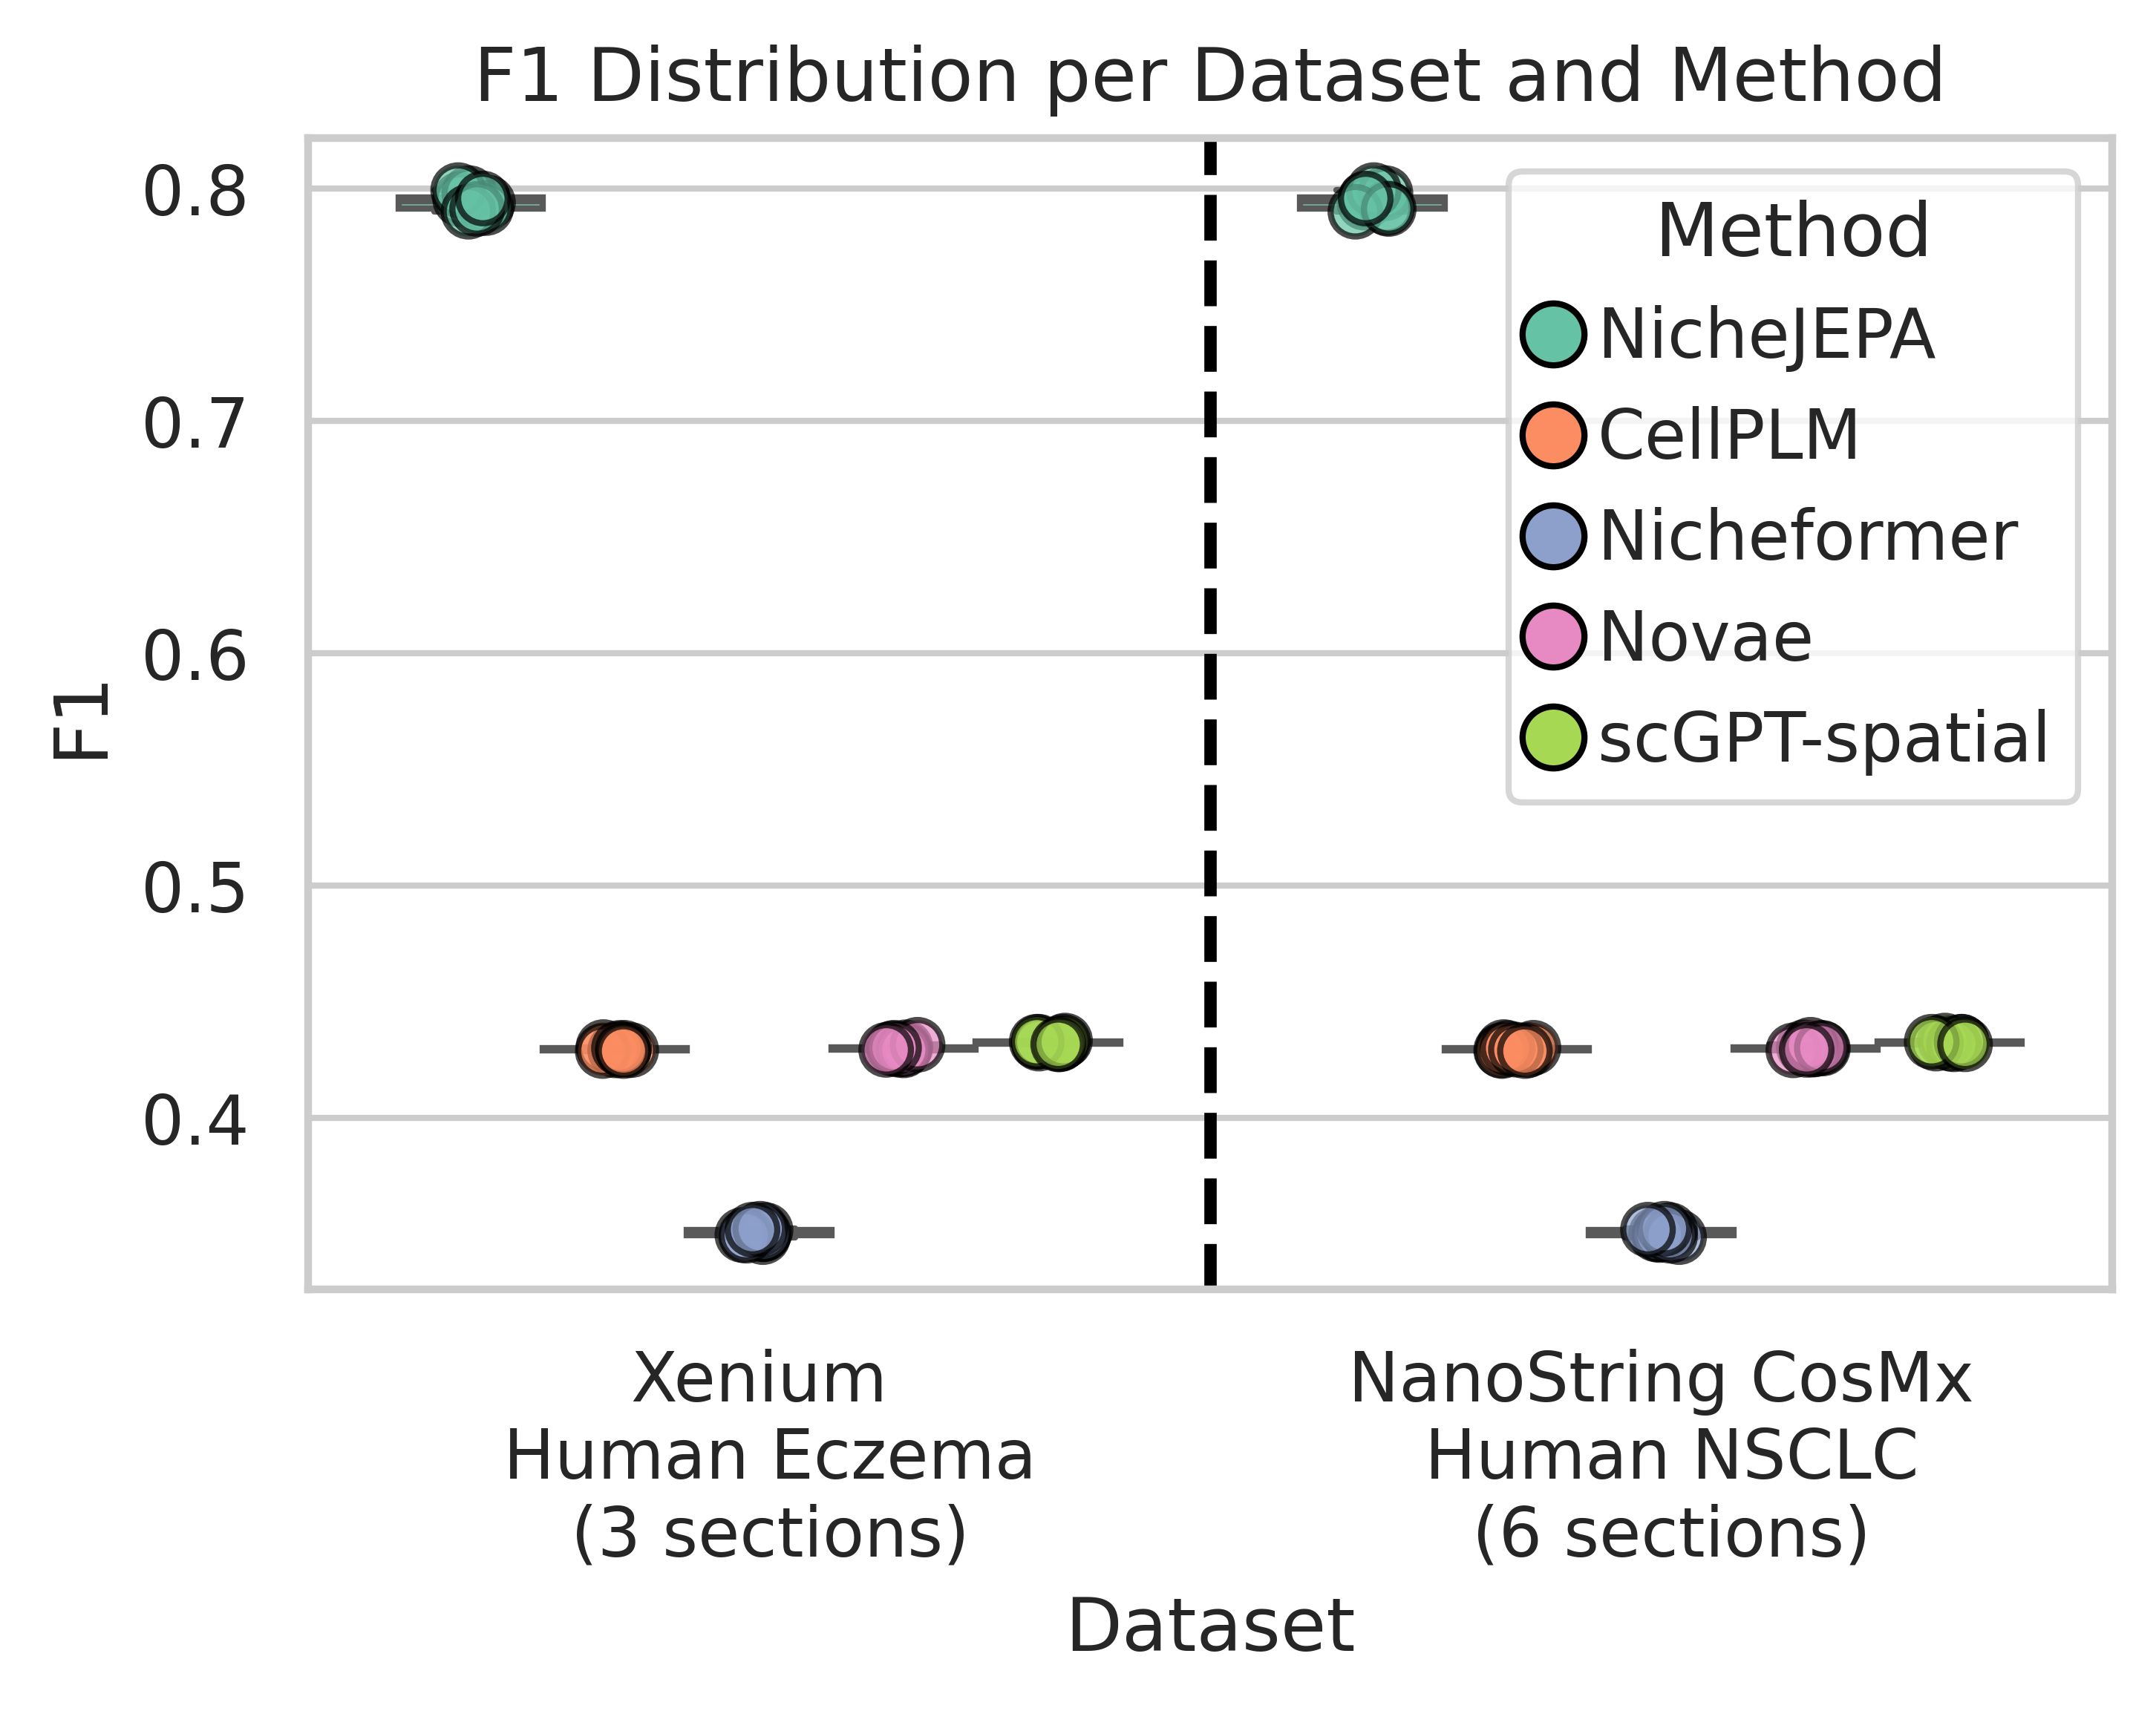

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# Update plot settings
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

for metric in ["F1"]:
    # Initialize the matplotlib figure with a specific size (wider plot)
    plt.figure(figsize=(5, 4))  # Increased width for a wider plot
    
    # Define a color palette (optional: customize as needed)
    palette = "Set2"
    
    # Create the boxplot
    ax = sns.boxplot(
        x='dataset',
        y=metric,
        hue='method',
        data=niche_transfer_df,
        palette=palette,
        dodge=True,
        showfliers=False  # Hide outliers for a cleaner look
    )
    
    # Overlay the scatter points with the same hue and palette
    sns.stripplot(
        x='dataset',
        y=metric,
        hue='method',
        data=niche_transfer_df,
        dodge=True,
        jitter=True,
        alpha=0.7,
        size=8,  # Increased dot size
        marker='o',
        edgecolor='black',  # Changed to black edges
        linewidth=1,        # Add linewidth for better edge visibility
        palette=palette,    # Ensure the palette matches the boxplot
        ax=ax
    )
    
    # Handle the legend to avoid duplicates
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))  # Remove duplicate labels
    
    # Remove the existing legend
    ax.legend_.remove()
    
    # Create custom legend handles with desired properties
    unique_methods = list(by_label.keys())
    palette_colors = sns.color_palette(palette, n_colors=len(unique_methods))
    
    custom_handles = [
        Line2D([0], [0], marker='o', color='w', label=method,
               markerfacecolor=palette_colors[i],
               markeredgecolor='black', markersize=10)
        for i, method in enumerate(unique_methods)
    ]
    
    # Add the custom legend
    ax.legend(handles=custom_handles, title='Method')
    
    # Add titles and labels with appropriate font sizes
    plt.title(f'{metric} Distribution per Dataset and Method')
    plt.xlabel('Dataset')
    plt.ylabel(metric)
    
    # Add black striped lines between x-axis values (datasets)
    num_datasets = len(niche_transfer_df['dataset'].unique())
    for i in range(num_datasets - 1):
        ax.axvline(x=i + 0.5, color='black', linestyle='--', linewidth=2)  # Dashed black lines
    
    # Adjust layout for better fit and prevent clipping of labels
    plt.tight_layout()
    
    # Display the plot
    plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison_niche_transfer_{metric.lower()}_{nichejepa_model_timestamp}.svg', dpi=300)
    plt.show()

## 6. Cell Type Label Transfer Metric Comparisons

In [95]:
def parse_classification_report(text):
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("precision"):
            continue

        parts = re.split(r"\s+", line)

        if parts[0] == "accuracy":
            rows.append({
                "label": "accuracy",
                "precision": None,
                "recall": None,
                "f1-score": float(parts[1]),
                "support": int(parts[2]),
            })
        elif parts[0] in {"macro", "weighted"}:
            rows.append({
                "label": f"{parts[0]} avg",
                "precision": float(parts[2]),
                "recall": float(parts[3]),
                "f1-score": float(parts[4]),
                "support": int(parts[5]),
            })
        else:
            rows.append({
                "label": parts[0],
                "precision": float(parts[1]),
                "recall": float(parts[2]),
                "f1-score": float(parts[3]),
                "support": int(parts[4]),
            })

    return rows

In [96]:
n_seeds = 8

f1_scores_nichejepa = []
f1_scores_cellplm = []
f1_scores_nicheformer = []
f1_scores_novae = []
f1_scores_scgpt_spatial = []

for dataset_name in [
    'xhs1000-39b_1p',
    'xhs1000-39b_1p'
    #'chl59-8b_1p'
    ]:

    method = "NicheJEPA"
    nichejepa_model_timestamp = '01112025_081731_614'
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{nichejepa_model_timestamp}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nichejepa.append(macro_f1)

    method = "CellPLM"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_cellplm.append(macro_f1)

    method = "nicheformer"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_nicheformer.append(macro_f1)

    method = "Novae"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_novae.append(macro_f1)

    method = "scGPT-spatial"
    
    for seed in range(n_seeds):
        file_path = f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_cell_type_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
    
        with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
            report_text = f.read()
        
        cls_report = parse_classification_report(report_text)
        
        macro_f1 = next(r["f1-score"] for r in cls_report if r["label"] == "macro avg")
        f1_scores_scgpt_spatial.append(macro_f1)

In [99]:
f1_lists = [
    f1_scores_nichejepa,
    f1_scores_cellplm,
    f1_scores_nicheformer,
    f1_scores_novae,
    f1_scores_scgpt_spatial
]

methods = [
    "NicheJEPA",
    "CellPLM",
    "Nicheformer",
    "Novae",
    "scGPT-spatial"
]

ds_lists = [[
    "Xenium\n Human Eczema\n (3 sections)"] * n_seeds + [
    "NanoString CosMx\n Human NSCLC\n (6 sections)"] * n_seeds] * 5

# Build dataframe
cell_type_transfer_df = pd.DataFrame({
    "F1": [f1 for sublist in f1_lists for f1 in sublist],
    "method": [m for m, sublist in zip(methods, f1_lists) for _ in sublist],
    "dataset": [ds for sublist in ds_lists for ds in sublist],
})

print(cell_type_transfer_df)

        F1         method                                        dataset
0   0.4736      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
1   0.4762      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
2   0.4759      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
3   0.4780      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
4   0.4778      NicheJEPA           Xenium\n Human Eczema\n (3 sections)
..     ...            ...                                            ...
75  0.2028  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
76  0.2015  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
77  0.2034  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
78  0.2024  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)
79  0.2054  scGPT-spatial  NanoString CosMx\n Human NSCLC\n (6 sections)

[80 rows x 3 columns]


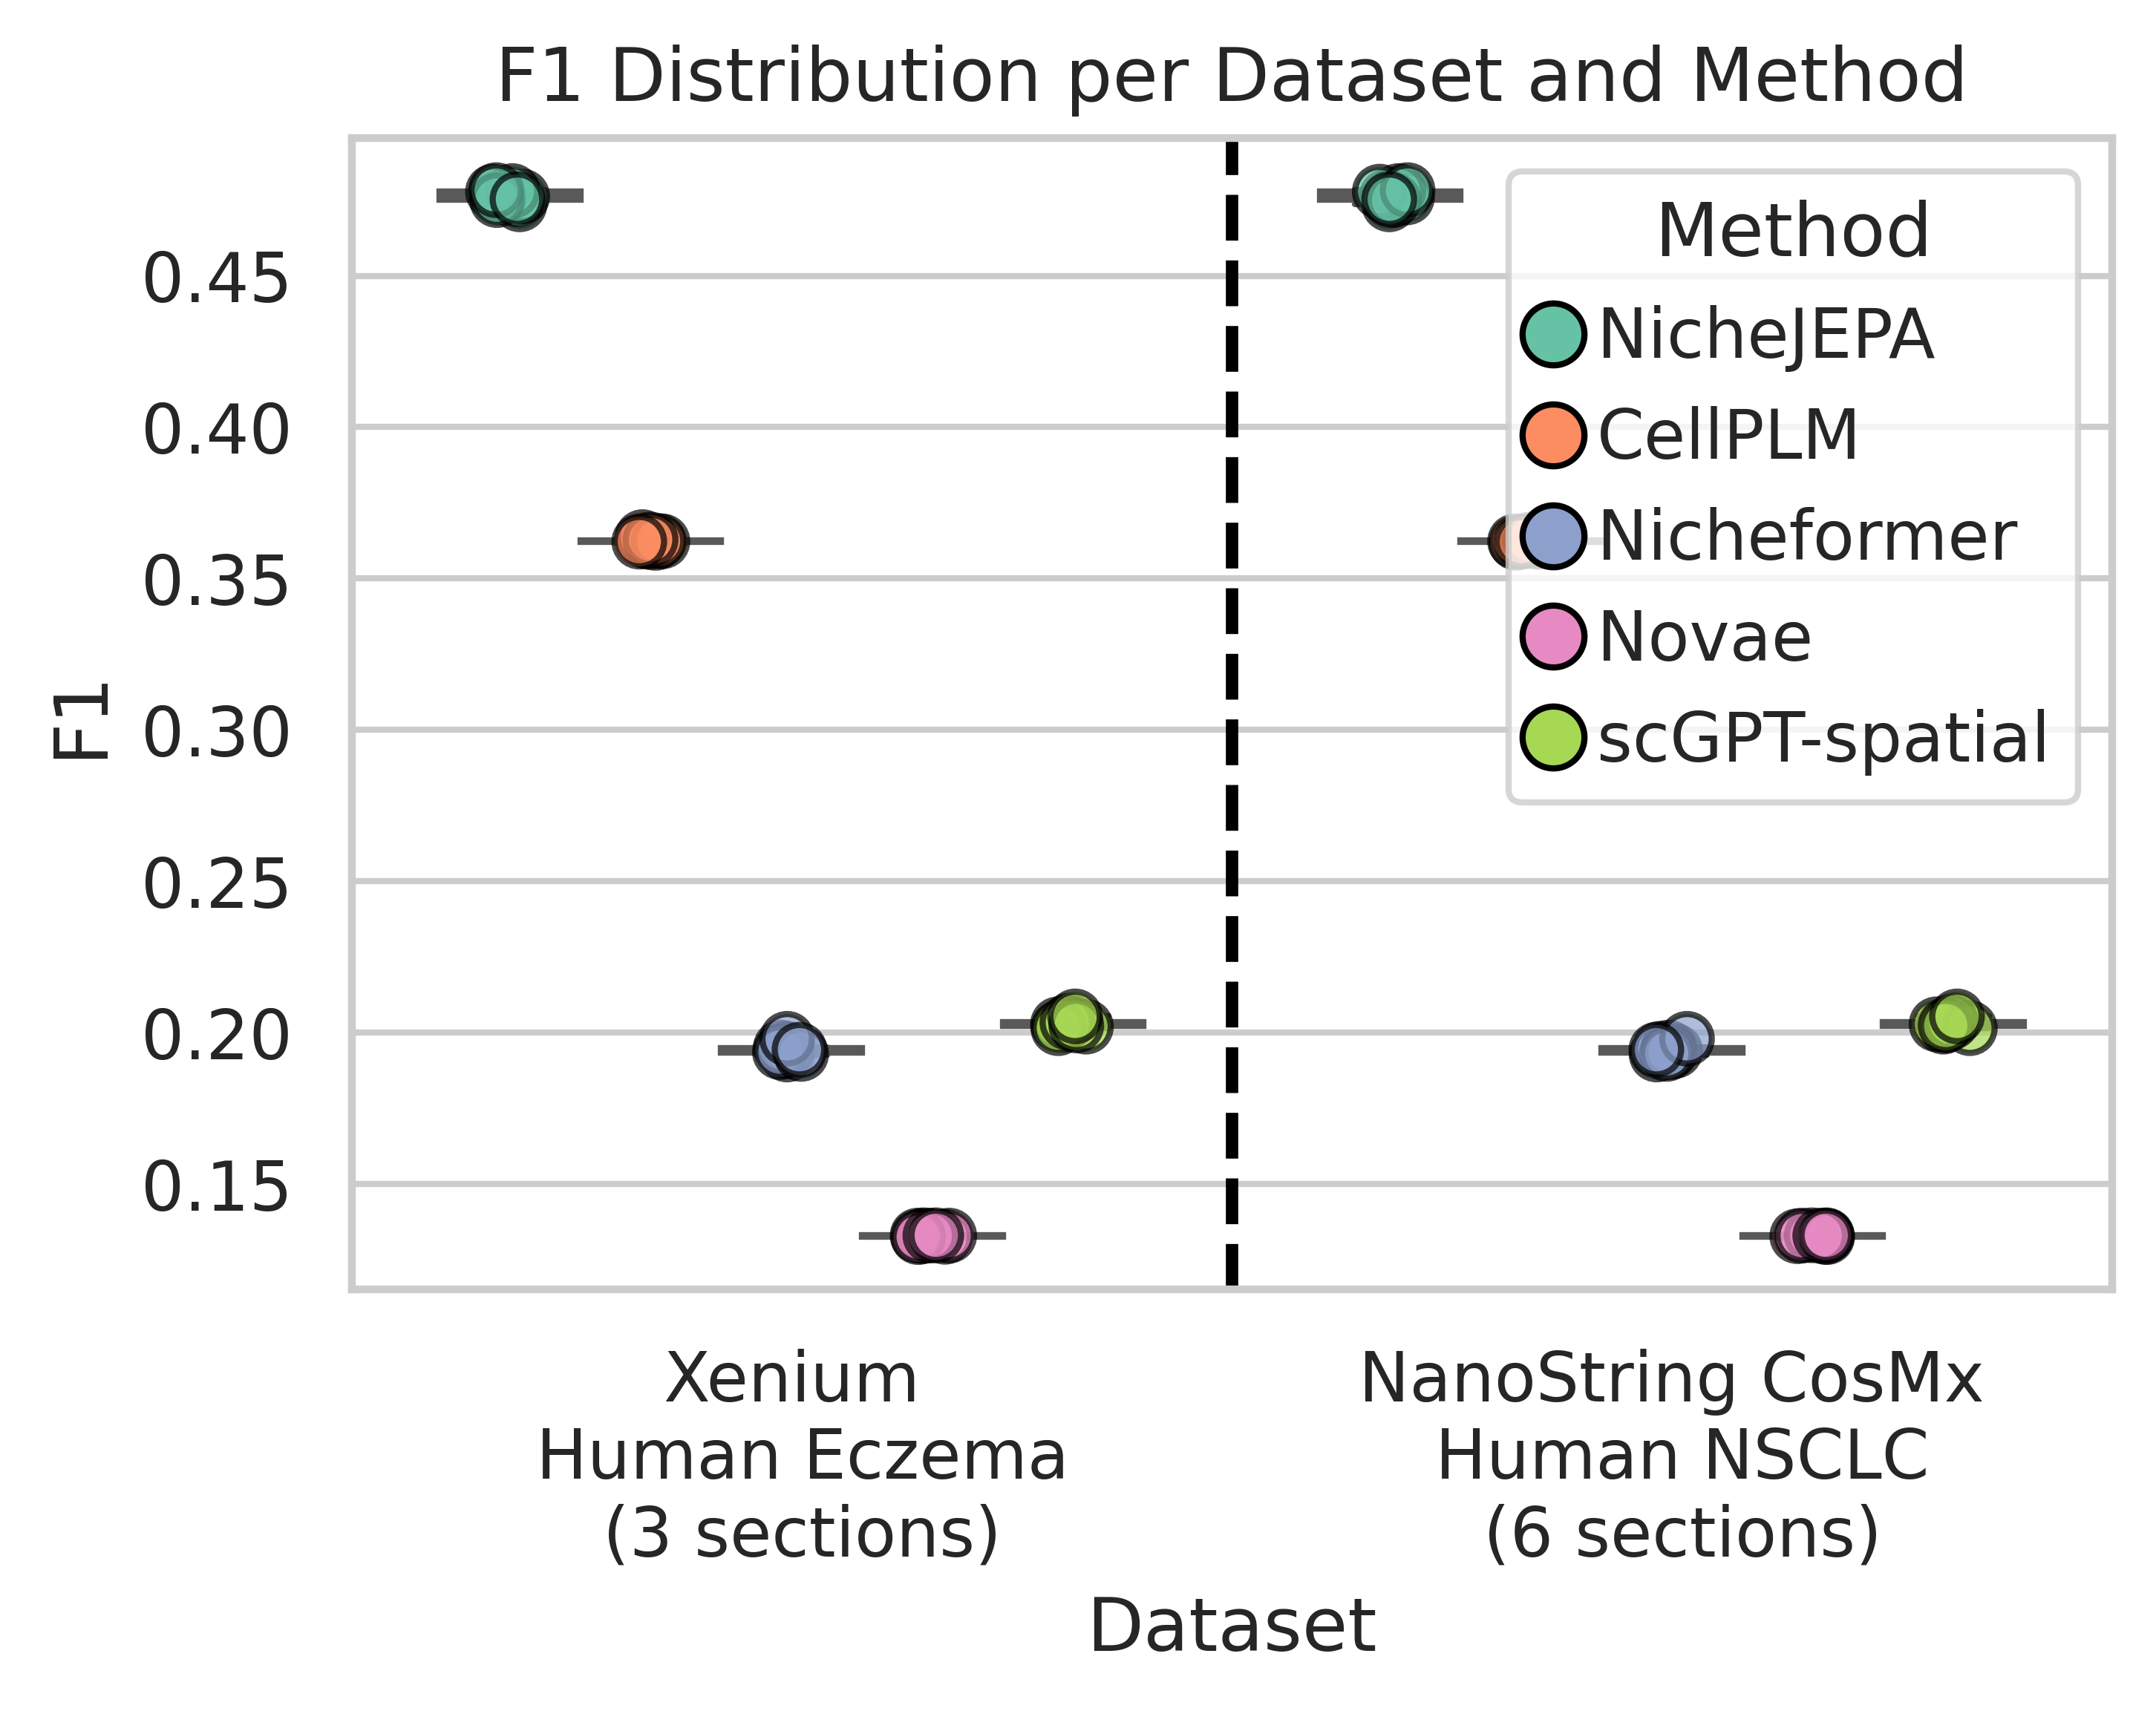

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# Update plot settings
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

for metric in ["F1"]:
    # Initialize the matplotlib figure with a specific size (wider plot)
    plt.figure(figsize=(5, 4))  # Increased width for a wider plot
    
    # Define a color palette (optional: customize as needed)
    palette = "Set2"
    
    # Create the boxplot
    ax = sns.boxplot(
        x='dataset',
        y=metric,
        hue='method',
        data=cell_type_transfer_df,
        palette=palette,
        dodge=True,
        showfliers=False  # Hide outliers for a cleaner look
    )
    
    # Overlay the scatter points with the same hue and palette
    sns.stripplot(
        x='dataset',
        y=metric,
        hue='method',
        data=cell_type_transfer_df,
        dodge=True,
        jitter=True,
        alpha=0.7,
        size=8,  # Increased dot size
        marker='o',
        edgecolor='black',  # Changed to black edges
        linewidth=1,        # Add linewidth for better edge visibility
        palette=palette,    # Ensure the palette matches the boxplot
        ax=ax
    )
    
    # Handle the legend to avoid duplicates
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))  # Remove duplicate labels
    
    # Remove the existing legend
    ax.legend_.remove()
    
    # Create custom legend handles with desired properties
    unique_methods = list(by_label.keys())
    palette_colors = sns.color_palette(palette, n_colors=len(unique_methods))
    
    custom_handles = [
        Line2D([0], [0], marker='o', color='w', label=method,
               markerfacecolor=palette_colors[i],
               markeredgecolor='black', markersize=10)
        for i, method in enumerate(unique_methods)
    ]
    
    # Add the custom legend
    ax.legend(handles=custom_handles, title='Method')
    
    # Add titles and labels with appropriate font sizes
    plt.title(f'{metric} Distribution per Dataset and Method')
    plt.xlabel('Dataset')
    plt.ylabel(metric)
    
    # Add black striped lines between x-axis values (datasets)
    num_datasets = len(cell_type_transfer_df['dataset'].unique())
    for i in range(num_datasets - 1):
        ax.axvline(x=i + 0.5, color='black', linestyle='--', linewidth=2)  # Dashed black lines
    
    # Adjust layout for better fit and prevent clipping of labels
    plt.tight_layout()
    
    # Display the plot
    plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison_cell_type_transfer_{metric.lower()}_{nichejepa_model_timestamp}.svg', dpi=300)
    plt.show()